In [ ]:
import h5py

h5_path = "../datasets/features/BC1/uni/SPA154.h5"

with h5py.File(h5_path, "r") as f:
    print(f.keys())
    gene_list = f["gene_list"][:]
    print(gene_list.shape)
    print("num genes:", len(gene_list))
    print(gene_list[:10])

<KeysViewHDF5 ['barcode', 'coords', 'count', 'exp', 'features', 'gene_list', 'patient', 'sample']>
<KeysViewHDF5 ['barcode', 'coords', 'count', 'exp', 'features', 'gene_list', 'patient', 'sample']>
(12041,)
num genes: 12041
[b'FO538757.1' b'SAMD11' b'NOC2L' b'KLHL17' b'PLEKHN1' b'PERM1' b'HES4'
 b'ISG15' b'AGRN' b'RNF223']


In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

cluster_dir = "../datasets/BC1/clustered/BC1"
h5ad_files = sorted(glob.glob(os.path.join(cluster_dir, "**", "*.h5ad"), recursive=True))

if not h5ad_files:
    raise FileNotFoundError(f"No h5ad files found under {cluster_dir}")

adata_list = []
for path in h5ad_files:
    ad = sc.read_h5ad(path)
    if "patient_id" not in ad.obs.columns:
        raise KeyError(f"{path} does not contain 'patient_id' in adata.obs")
    if "sample_id" not in ad.obs.columns:
        raise KeyError(f"{path} does not contain 'sample_id' in adata.obs")
    adata_list.append(ad)

adata = sc.concat(
    adata_list,
    join="inner",
    index_unique=None,
    merge="same",
)

cluster_cols = sorted([col for col in adata.obs.columns if col.endswith("_cluster")])
if not cluster_cols:
    raise ValueError("No cluster columns found in adata.obs")

patient_col = "patient_id"
summary_rows = []
for cluster_col in cluster_cols:
    feature_name = cluster_col.removesuffix("_cluster")
    for patient_id in adata.obs[patient_col].dropna().unique():
        sub = adata[adata.obs[patient_col] == patient_id]
        cluster_values = sub.obs[cluster_col].dropna().astype(str)
        summary_rows.append(
            {
                "patient_id": patient_id,
                "feature": feature_name,
                "n_clusters": int(cluster_values.nunique()),
            }
        )

summary_df = pd.DataFrame(summary_rows)
cluster_count_table = summary_df.pivot(
    index="patient_id",
    columns="feature",
    values="n_clusters",
).fillna(0).astype(int)

print("每个 patient 在每个 feature 下的 cluster 数量：")
display(cluster_count_table)



每个 patient 在每个 feature 下的 cluster 数量：


feature,conch_0p5,midnight_0p5,resnet50_0p5,uni_0p5
patient_id,,,,
Patient A,5,7,5,5
Patient B,5,6,6,5
Patient C,4,5,5,4
Patient D,6,6,5,6
Patient E,3,7,6,7
Patient F,4,7,5,6
Patient G,4,7,6,7
Patient H,5,8,6,7


每个 rank list 的 gene 数量：


conch       250
uni         250
resnet50    250
midnight    250
Name: n_genes, dtype: int64

两两 overlap 数量 inclusive：


,conch,uni,resnet50,midnight
conch,250,204,201,205
uni,204,250,207,205
resnet50,201,207,250,207
midnight,205,205,207,250


2/3/4 个 rank list 的 overlap 数量 inclusive：


,n_lists,lists,n_overlap_inclusive
0,2,uni & resnet50,207
1,2,resnet50 & midnight,207
2,2,conch & midnight,205
3,2,uni & midnight,205
4,2,conch & uni,204
5,2,conch & resnet50,201
6,3,conch & resnet50 & midnight,188
7,3,uni & resnet50 & midnight,187
8,3,conch & uni & midnight,186
9,3,conch & uni & resnet50,185


容斥分区数量 exact，仅展示属于至少 2 个 list 的 gene：


,lists,n_lists,n_genes_exact
0,conch & uni & resnet50 & midnight,4,176
1,conch & resnet50 & midnight,3,12
2,uni & resnet50 & midnight,3,11
3,conch & uni & midnight,3,10
4,conch & uni & resnet50,3,9
5,uni & resnet50,2,11
6,conch & uni,2,9
7,uni & midnight,2,8
8,resnet50 & midnight,2,8
9,conch & midnight,2,7


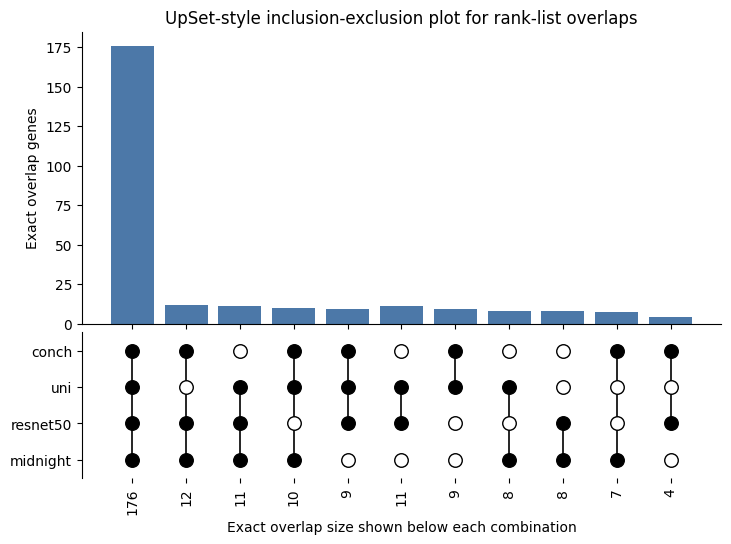

In [1]:
import json
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

rank_dir_candidates = [Path("../datasets/rank_list"), Path("datasets/rank_list")]
rank_dir = next((path for path in rank_dir_candidates if path.exists()), rank_dir_candidates[0])
rank_files = {
    "conch": rank_dir / "conch_fscore.json",
    "uni": rank_dir / "uni_fscore.json",
    "resnet50": rank_dir / "resnet50_fscore.json",
    "midnight": rank_dir / "midnight_fscore.json",
}

gene_sets = {}
for name, rank_path in rank_files.items():
    with open(rank_path, "r", encoding="utf-8") as f:
        gene_sets[name] = set(json.load(f))

names = list(gene_sets.keys())

print("每个 rank list 的 gene 数量：")
display(pd.Series({name: len(genes) for name, genes in gene_sets.items()}, name="n_genes"))

# Inclusive overlap: A & B includes genes that may also appear in C/D.
pairwise_df = pd.DataFrame(index=names, columns=names, dtype=int)
for row_name, row_genes in gene_sets.items():
    for col_name, col_genes in gene_sets.items():
        pairwise_df.loc[row_name, col_name] = len(row_genes & col_genes)

print("两两 overlap 数量 inclusive：")
display(pairwise_df.astype(int))

combo_rows = []
for n_lists in range(2, len(names) + 1):
    for combo in combinations(names, n_lists):
        overlap = set.intersection(*(gene_sets[name] for name in combo))
        combo_rows.append(
            {
                "n_lists": n_lists,
                "lists": " & ".join(combo),
                "n_overlap_inclusive": len(overlap),
            }
        )

combo_df = (
    pd.DataFrame(combo_rows)
    .sort_values(["n_lists", "n_overlap_inclusive"], ascending=[True, False])
    .reset_index(drop=True)
)

print("2/3/4 个 rank list 的 overlap 数量 inclusive：")
display(combo_df)

# Exact overlap partitions for an UpSet-style inclusion-exclusion plot.
# Example: conch & uni means genes in exactly conch and uni, not in the others.
all_genes = set.union(*gene_sets.values())
pattern_counts = Counter(
    tuple(name for name in names if gene in gene_sets[name])
    for gene in all_genes
)

exact_df = pd.DataFrame(
    [
        {
            "members": pattern,
            "lists": " & ".join(pattern),
            "n_lists": len(pattern),
            "n_genes_exact": count,
        }
        for pattern, count in pattern_counts.items()
        if len(pattern) >= 2
    ]
).sort_values(["n_lists", "n_genes_exact"], ascending=[False, False]).reset_index(drop=True)

print("容斥分区数量 exact，仅展示属于至少 2 个 list 的 gene：")
display(exact_df[["lists", "n_lists", "n_genes_exact"]])

fig_width = max(8, len(exact_df) * 0.75)
fig = plt.figure(figsize=(fig_width, 5.8))
grid = fig.add_gridspec(2, 1, height_ratios=[3.2, 1.6], hspace=0.04)
ax_bar = fig.add_subplot(grid[0])
ax_matrix = fig.add_subplot(grid[1], sharex=ax_bar)

x = list(range(len(exact_df)))
ax_bar.bar(x, exact_df["n_genes_exact"], color="#4C78A8")
ax_bar.set_ylabel("Exact overlap genes")
ax_bar.set_title("UpSet-style inclusion-exclusion plot for rank-list overlaps")
ax_bar.tick_params(axis="x", labelbottom=False)

for i, members in enumerate(exact_df["members"]):
    member_y = [names.index(name) for name in members]
    ax_matrix.plot([i, i], [min(member_y), max(member_y)], color="black", linewidth=1.2)
    for y, name in enumerate(names):
        selected = name in members
        ax_matrix.scatter(
            i,
            y,
            s=95,
            color="black" if selected else "white",
            edgecolor="black",
            linewidth=1,
            zorder=3,
        )

ax_matrix.set_yticks(range(len(names)))
ax_matrix.set_yticklabels(names)
ax_matrix.set_xticks(x)
ax_matrix.set_xticklabels(exact_df["n_genes_exact"], rotation=90)
ax_matrix.set_xlabel("Exact overlap size shown below each combination")
ax_matrix.set_ylim(-0.5, len(names) - 0.5)
ax_matrix.invert_yaxis()
ax_matrix.spines[["top", "right", "bottom"]].set_visible(False)
ax_bar.spines[["top", "right"]].set_visible(False)

plt.show()


Baseline PCC: ../results/fscore_pcc.csv
PCA50 PCC:   ../fscore_PCA50_pcc.csv
Matched methods: 16


,Top_K,method,method_pca50,PCC_base,PCC_PCA50,delta_PCA50_minus_base
4,top10,Midnight_Conch,Midnight_ConchFscore0P5,0.408006,0.413007,0.005001
5,top10,Midnight_Midnight,Midnight_MidnightFscore0P5,0.403365,0.407685,0.004319
2,top10,Conch_Resnet,Conch_Resnet50Fscore0P5,0.401918,0.405705,0.003787
10,top10,Resnet_Resnet,Resnet_Resnet50Fscore0P5,0.383164,0.386044,0.002879
14,top10,Uni_Resnet,Uni_Resnet50Fscore0P5,0.419425,0.421894,0.002469
...,...,...,...,...,...,...
63,top50,Uni_Uni,Uni_UniFscore0P5,0.350483,0.349952,-0.000531
56,top50,Resnet_Conch,Resnet_ConchFscore0P5,0.316643,0.316060,-0.000584
61,top50,Uni_Midnight,Uni_MidnightFscore0P5,0.346881,0.345939,-0.000942
57,top50,Resnet_Midnight,Resnet_MidnightFscore0P5,0.315919,0.314340,-0.001579


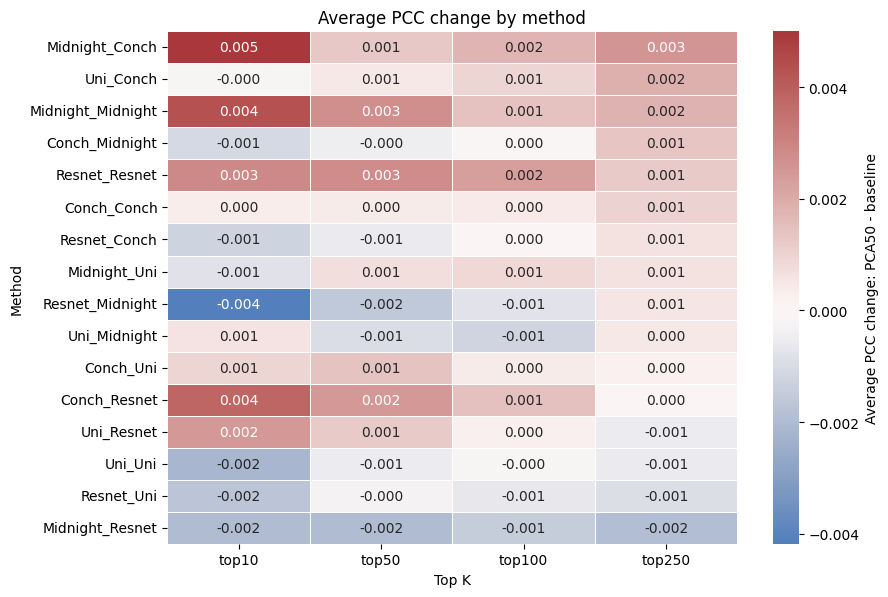

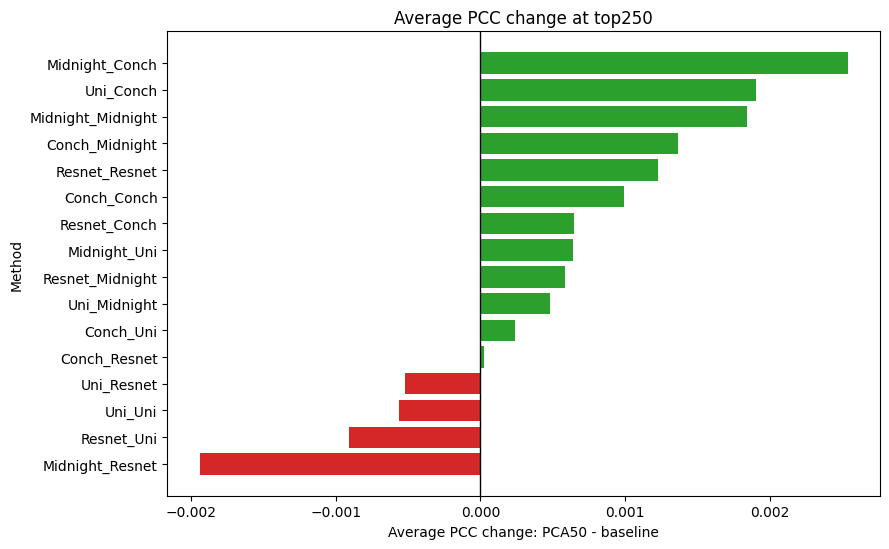

In [1]:
# Compare Average PCC between fscore_pcc and fscore_PCA50_pcc
# Positive delta means PCA50 is better than the baseline CSV.

from pathlib import Path
from difflib import get_close_matches
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def first_existing(candidates):
    for path in candidates:
        path = Path(path)
        if path.exists():
            return path
    raise FileNotFoundError(f"None of these files exist: {[str(p) for p in candidates]}")


base_csv = first_existing([
    "fscore_pcc.csv",
    "../fscore_pcc.csv",
    "results/fscore_pcc.csv",
    "../results/fscore_pcc.csv",
    "fscore_pcc_0p3.csv",
    "../fscore_pcc_0p3.csv",
])
pca50_csv = first_existing([
    "fscore_PCA50_pcc.csv",
    "../fscore_PCA50_pcc.csv",
    "results/fscore_PCA50_pcc.csv",
    "../results/fscore_PCA50_pcc.csv",
])

print(f"Baseline PCC: {base_csv}")
print(f"PCA50 PCC:   {pca50_csv}")


def canonical_method_name(column):
    """Normalize method names so columns with slightly different labels can match."""
    parts = []
    for token in str(column).split("_"):
        token = token.strip().lower()
        token = re.sub(r"fscore.*$", "", token)
        token = re.sub(r"pca\d+", "", token)
        token = re.sub(r"[^a-z0-9]", "", token)
        if not token:
            continue
        if token in {"resnet50", "resnet"}:
            token = "resnet"
        parts.append(token)
    return "_".join(parts)


def load_average_pcc(csv_path, value_name):
    df = pd.read_csv(csv_path)
    id_cols = {"Patient", "Top_K"}
    value_cols = [col for col in df.columns if col not in id_cols]

    avg_df = df[df["Patient"].astype(str).str.lower().eq("average")].copy()
    if avg_df.empty:
        avg_df = df.groupby("Top_K", as_index=False)[value_cols].mean(numeric_only=True)
        avg_df["Patient"] = "Average"

    long_df = avg_df.melt(
        id_vars=["Patient", "Top_K"],
        value_vars=value_cols,
        var_name="method_raw",
        value_name=value_name,
    )
    long_df["method_key"] = long_df["method_raw"].map(canonical_method_name)
    return long_df


base_long = load_average_pcc(base_csv, "PCC_base")
pca50_long = load_average_pcc(pca50_csv, "PCC_PCA50")

# Exact match after normalization first, then fuzzy match remaining PCA50 columns.
base_keys = set(base_long["method_key"])
pca_keys = set(pca50_long["method_key"])
fuzzy_map = {key: key for key in pca_keys if key in base_keys}
for key in sorted(pca_keys - base_keys):
    match = get_close_matches(key, base_keys, n=1, cutoff=0.82)
    if match:
        fuzzy_map[key] = match[0]

base_cmp = base_long.copy()
base_cmp["compare_key"] = base_cmp["method_key"]
pca_cmp = pca50_long[pca50_long["method_key"].isin(fuzzy_map)].copy()
pca_cmp["compare_key"] = pca_cmp["method_key"].map(fuzzy_map)

base_cmp = (
    base_cmp.groupby(["Top_K", "compare_key"], as_index=False)
    .agg(PCC_base=("PCC_base", "mean"), method_base=("method_raw", "first"))
)
pca_cmp = (
    pca_cmp.groupby(["Top_K", "compare_key"], as_index=False)
    .agg(PCC_PCA50=("PCC_PCA50", "mean"), method_pca50=("method_raw", "first"))
)

compare_df = base_cmp.merge(pca_cmp, on=["Top_K", "compare_key"], how="inner")
compare_df["delta_PCA50_minus_base"] = compare_df["PCC_PCA50"] - compare_df["PCC_base"]
compare_df["method"] = compare_df["method_base"]

unmatched_base = sorted(base_keys - set(fuzzy_map.values()))
unmatched_pca50 = sorted(pca_keys - set(fuzzy_map))
print(f"Matched methods: {compare_df['compare_key'].nunique()}")
if unmatched_base:
    print("Baseline only:", unmatched_base)
if unmatched_pca50:
    print("PCA50 only:", unmatched_pca50)

show_cols = ["Top_K", "method", "method_pca50", "PCC_base", "PCC_PCA50", "delta_PCA50_minus_base"]
display(compare_df.sort_values(["Top_K", "delta_PCA50_minus_base"], ascending=[True, False])[show_cols])

# Heatmap: PCA50 - baseline for every matched method and Top_K.
top_k_order = ["top10", "top50", "top100", "top250"]
rank_top_k = "top250" if "top250" in set(compare_df["Top_K"]) else sorted(compare_df["Top_K"].unique())[-1]
method_order = (
    compare_df[compare_df["Top_K"].eq(rank_top_k)]
    .sort_values("delta_PCA50_minus_base", ascending=False)["method"]
    .tolist()
)

heatmap_df = compare_df.pivot(index="method", columns="Top_K", values="delta_PCA50_minus_base")
ordered_cols = [col for col in top_k_order if col in heatmap_df.columns]
ordered_cols += [col for col in heatmap_df.columns if col not in ordered_cols]
heatmap_df = heatmap_df.reindex(index=method_order, columns=ordered_cols)

plt.figure(figsize=(9, max(5, 0.38 * len(heatmap_df))))
sns.heatmap(
    heatmap_df,
    center=0,
    cmap="vlag",
    annot=True,
    fmt=".3f",
    linewidths=0.5,
    cbar_kws={"label": "Average PCC change: PCA50 - baseline"},
)
plt.title("Average PCC change by method")
plt.xlabel("Top K")
plt.ylabel("Method")
plt.tight_layout()
plt.show()

# Bar plot for one Top_K, defaulting to top250 when available.
bar_df = compare_df[compare_df["Top_K"].eq(rank_top_k)].sort_values("delta_PCA50_minus_base")
plt.figure(figsize=(9, max(4, 0.35 * len(bar_df))))
colors = ["#D62728" if value < 0 else "#2CA02C" for value in bar_df["delta_PCA50_minus_base"]]
plt.barh(bar_df["method"], bar_df["delta_PCA50_minus_base"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Average PCC change: PCA50 - baseline")
plt.ylabel("Method")
plt.title(f"Average PCC change at {rank_top_k}")
plt.tight_layout()
plt.show()


Baseline PCC: ../results/fscore_pcc.csv
0p3 PCC:      ../fscore_pcc_0p3.csv
Matched methods: 12


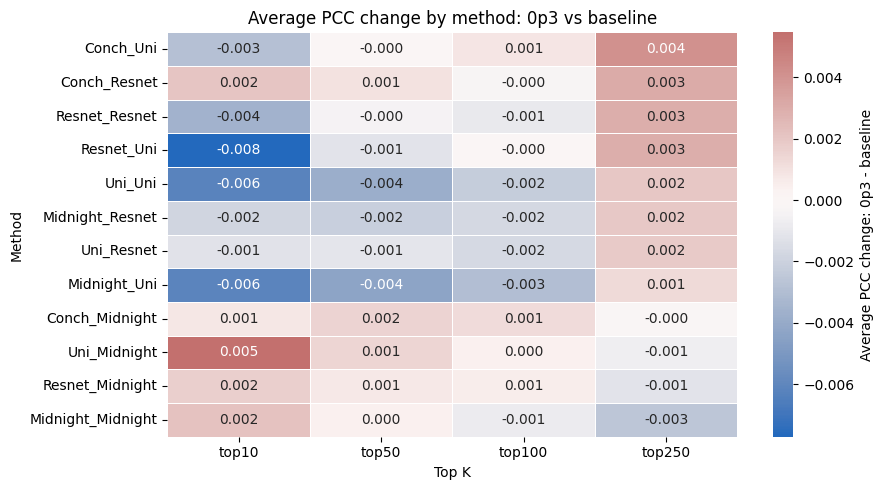

In [1]:
# Compare Average PCC between fscore_pcc and fscore_pcc_0p3
# Positive delta means 0p3 is better than the baseline CSV.

from pathlib import Path
from difflib import get_close_matches
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def first_existing(candidates):
    for path in candidates:
        path = Path(path)
        if path.exists():
            return path
    raise FileNotFoundError(f"None of these files exist: {[str(p) for p in candidates]}")


base_csv = first_existing([
    "fscore_pcc.csv",
    "../fscore_pcc.csv",
    "results/fscore_pcc.csv",
    "../results/fscore_pcc.csv",
])
resolution_csv = first_existing([
    "fscore_pcc_0p3.csv",
    "../fscore_pcc_0p3.csv",
    "results/fscore_pcc_0p3.csv",
    "../results/fscore_pcc_0p3.csv",
])

print(f"Baseline PCC: {base_csv}")
print(f"0p3 PCC:      {resolution_csv}")


def canonical_method_name(column):
    parts = []
    for token in str(column).split("_"):
        token = token.strip().lower()
        token = re.sub(r"fscore.*$", "", token)
        token = re.sub(r"pca\d+", "", token)
        token = re.sub(r"[^a-z0-9]", "", token)
        if not token:
            continue
        if token in {"resnet50", "resnet"}:
            token = "resnet"
        parts.append(token)
    return "_".join(parts)


def load_average_pcc(csv_path, value_name):
    df = pd.read_csv(csv_path)
    id_cols = {"Patient", "Top_K"}
    value_cols = [col for col in df.columns if col not in id_cols]

    avg_df = df[df["Patient"].astype(str).str.lower().eq("average")].copy()
    if avg_df.empty:
        avg_df = df.groupby("Top_K", as_index=False)[value_cols].mean(numeric_only=True)
        avg_df["Patient"] = "Average"

    long_df = avg_df.melt(
        id_vars=["Patient", "Top_K"],
        value_vars=value_cols,
        var_name="method_raw",
        value_name=value_name,
    )
    long_df["method_key"] = long_df["method_raw"].map(canonical_method_name)
    return long_df


base_long = load_average_pcc(base_csv, "PCC_base")
res_long = load_average_pcc(resolution_csv, "PCC_0p3")

base_keys = set(base_long["method_key"])
res_keys = set(res_long["method_key"])
fuzzy_map = {key: key for key in res_keys if key in base_keys}
for key in sorted(res_keys - base_keys):
    match = get_close_matches(key, base_keys, n=1, cutoff=0.82)
    if match:
        fuzzy_map[key] = match[0]

base_cmp = base_long.copy()
base_cmp["compare_key"] = base_cmp["method_key"]
res_cmp = res_long[res_long["method_key"].isin(fuzzy_map)].copy()
res_cmp["compare_key"] = res_cmp["method_key"].map(fuzzy_map)

base_cmp = (
    base_cmp.groupby(["Top_K", "compare_key"], as_index=False)
    .agg(PCC_base=("PCC_base", "mean"), method_base=("method_raw", "first"))
)
res_cmp = (
    res_cmp.groupby(["Top_K", "compare_key"], as_index=False)
    .agg(PCC_0p3=("PCC_0p3", "mean"), method_0p3=("method_raw", "first"))
)

compare_df = base_cmp.merge(res_cmp, on=["Top_K", "compare_key"], how="inner")
compare_df["delta_0p3_minus_base"] = compare_df["PCC_0p3"] - compare_df["PCC_base"]
compare_df["method"] = compare_df["method_base"]

print(f"Matched methods: {compare_df['compare_key'].nunique()}")

# Heatmap only: 0p3 - baseline for every matched method and Top_K.
top_k_order = ["top10", "top50", "top100", "top250"]
rank_top_k = "top250" if "top250" in set(compare_df["Top_K"]) else sorted(compare_df["Top_K"].unique())[-1]
method_order = (
    compare_df[compare_df["Top_K"].eq(rank_top_k)]
    .sort_values("delta_0p3_minus_base", ascending=False)["method"]
    .tolist()
)

heatmap_df = compare_df.pivot(index="method", columns="Top_K", values="delta_0p3_minus_base")
ordered_cols = [col for col in top_k_order if col in heatmap_df.columns]
ordered_cols += [col for col in heatmap_df.columns if col not in ordered_cols]
heatmap_df = heatmap_df.reindex(index=method_order, columns=ordered_cols)

plt.figure(figsize=(9, max(5, 0.38 * len(heatmap_df))))
sns.heatmap(
    heatmap_df,
    center=0,
    cmap="vlag",
    annot=True,
    fmt=".3f",
    linewidths=0.5,
    cbar_kws={"label": "Average PCC change: 0p3 - baseline"},
)
plt.title("Average PCC change by method: 0p3 vs baseline")
plt.xlabel("Top K")
plt.ylabel("Method")
plt.tight_layout()
plt.show()


Using PCC file: ../results/fscore_pcc.csv


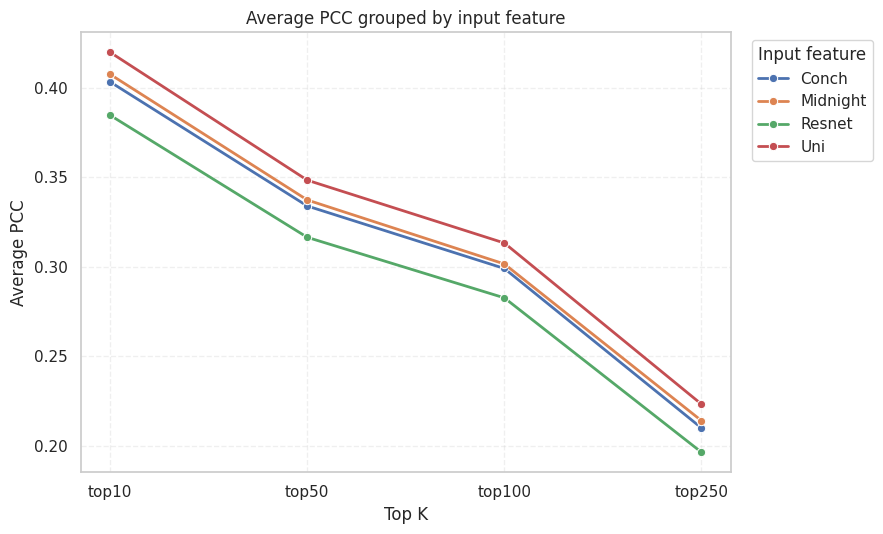

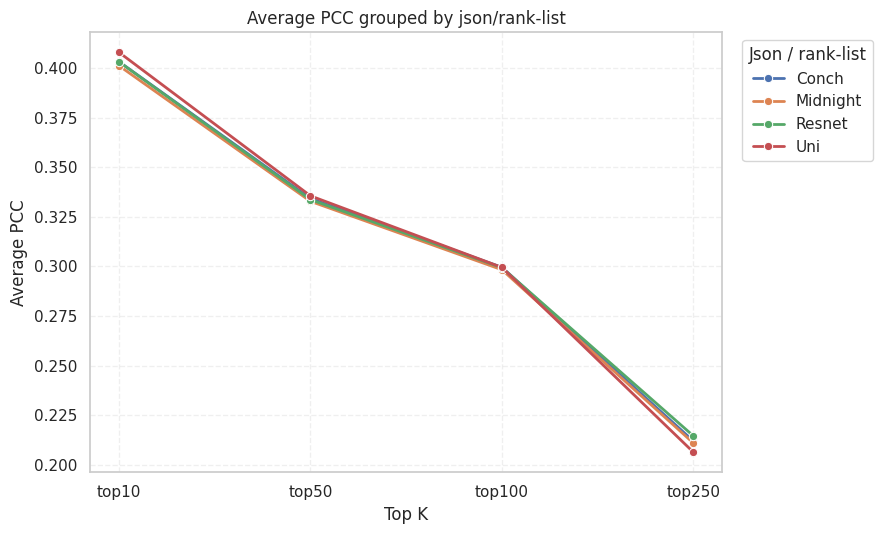

In [3]:
# Internal comparison within fscore_pcc
# View 1: group by input feature, averaging over all json/rank-list columns.
# View 2: group by json/rank-list, averaging over all input features.

from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

plt.close("all")
sns.set_theme(style="whitegrid")


def first_existing(candidates):
    for path in candidates:
        path = Path(path)
        if path.exists():
            return path
    raise FileNotFoundError(f"None of these files exist: {[str(p) for p in candidates]}")


pcc_csv = first_existing([
    "fscore_pcc.csv",
    "../fscore_pcc.csv",
    "results/fscore_pcc.csv",
    "../results/fscore_pcc.csv",
])
print(f"Using PCC file: {pcc_csv}")


def display_name(token):
    token = str(token).strip()
    token = re.sub(r"fscore.*$", "", token, flags=re.IGNORECASE)
    token = token.replace("Resnet50", "Resnet").replace("resnet50", "resnet")
    return token


def split_method_column(column):
    """Split columns like Conch_UniFscore0P3 into input_feature and json_group."""
    parts = str(column).split("_", 1)
    if len(parts) == 1:
        return display_name(parts[0]), "Unknown"
    input_feature, json_group = parts
    return display_name(input_feature), display_name(json_group)


df = pd.read_csv(pcc_csv)
value_cols = [col for col in df.columns if col not in {"Patient", "Top_K"}]

avg_df = df[df["Patient"].astype(str).str.lower().eq("average")].copy()
if avg_df.empty:
    avg_df = df.groupby("Top_K", as_index=False)[value_cols].mean(numeric_only=True)
    avg_df["Patient"] = "Average"

long_df = avg_df.melt(
    id_vars=["Patient", "Top_K"],
    value_vars=value_cols,
    var_name="method_raw",
    value_name="Mean_PCC",
)
parsed = long_df["method_raw"].apply(split_method_column)
long_df["input_feature"] = parsed.map(lambda item: item[0])
long_df["json_group"] = parsed.map(lambda item: item[1])

top_k_order = ["top10", "top50", "top100", "top250"]
existing_top_k = [top_k for top_k in top_k_order if top_k in set(long_df["Top_K"])]
existing_top_k += [top_k for top_k in long_df["Top_K"].unique() if top_k not in existing_top_k]
long_df["Top_K"] = pd.Categorical(long_df["Top_K"], categories=existing_top_k, ordered=True)

feature_trend = (
    long_df.groupby(["Top_K", "input_feature"], as_index=False, observed=True)["Mean_PCC"]
    .mean()
    .sort_values(["input_feature", "Top_K"])
)
json_trend = (
    long_df.groupby(["Top_K", "json_group"], as_index=False, observed=True)["Mean_PCC"]
    .mean()
    .sort_values(["json_group", "Top_K"])
)

# Figure 1: average trend grouped by input feature.
plt.figure(figsize=(9, 5.5))
sns.lineplot(
    data=feature_trend,
    x="Top_K",
    y="Mean_PCC",
    hue="input_feature",
    marker="o",
    linewidth=2,
    errorbar=None,
    estimator=None,
)
plt.title("Average PCC grouped by input feature")
plt.xlabel("Top K")
plt.ylabel("Average PCC")
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(title="Input feature", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Figure 2: average trend grouped by json/rank-list.
plt.figure(figsize=(9, 5.5))
sns.lineplot(
    data=json_trend,
    x="Top_K",
    y="Mean_PCC",
    hue="json_group",
    marker="o",
    linewidth=2,
    errorbar=None,
    estimator=None,
)
plt.title("Average PCC grouped by json/rank-list")
plt.xlabel("Top K")
plt.ylabel("Average PCC")
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(title="Json / rank-list", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
